<div align="center">

<img src="img/ITQ.png" width="400">

# NORMALIZACIÓN Y ESTANDARIZACIÓN DE DATOS MÉDICOS CON CRISP-DM

**Carrera:** Inteligencia Artificial

**Asignatura:** Fundamentos de Machine Learning

**Docente:** Ing. Elvis Pachacama Cabezas

**Estudiante:** Nikolay Misael De La Cruz Melendres

**Fecha:** 09 de noviembre de 2026

**Repositorio:** [Fundamentos de Machine Learning](https://github.com/NikolayDlc/fundamentosMachine)

# Objetivo y descripción de la práctica

## Objetivo general
Aplicar las fases de comprensión del negocio y comprensión de los datos de CRISP-DM, preparando variables cuantitativas de un dataset médico mediante normalización Min-Max y estandarización Z-score.
## Antecedentes
El dataset Diabetes 130-US Hospitals for Years 1999–2008, publicado por UCI Machine Learning Repository, contiene 101 766 registros de hospitalizaciones de pacientes con diabetes. Cada fila representa una hospitalización y no necesariamente un paciente distinto.
## Planteamiento del problema
Un equipo hospitalario desea conocer las características de las hospitalizaciones y explorar las categorías de readmisión. Para ello, es necesario revisar los datos y preparar sus variables numéricas antes de desarrollar futuros modelos de Machine Learning.

# Paso 1. Descarga y registro de la fuente

## Consigna

Descargar el conjunto de datos médicos desde UCI Machine Learning Repository, verificar sus dimensiones, visualizar sus primeros registros y conservar una copia original.

**Fuente oficial:** https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

Primero se instalará la librería de descarga y posteriormente se utilizarán Pandas y las demás bibliotecas necesarias.


In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Bibliotecas utilizadas en la práctica

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime
from importlib.metadata import version
from IPython.display import display
from sklearn import preprocessing

# Crear carpeta para los archivos de resultados
os.makedirs("dataset", exist_ok=True)

In [3]:
from ucimlrepo import fetch_ucirepo

# Descargar desde UCI y mantener una copia original sin modificar.
dataset = fetch_ucirepo(id=296)
df = dataset.data.original.copy()

print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."
display(df.head())

# Diccionario oficial, para contrastar su significado.
display(dataset.variables)

# Guardar la copia original solicitada por el profesor.
df.to_csv("dataset/hospitalizaciones_diabetes_original.csv", index=False)


C:\Users\PC\AppData\Roaming\Python\Python314\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


In [4]:
# Registrar fecha de ejecución
print("Fecha de ejecución:", datetime.now())

# Versión de Python
print("Python:", sys.version.split()[0])

# Versiones de las bibliotecas
for paquete in [
    "ucimlrepo",
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn"
]:
    print(paquete, ":", version(paquete))

# Dimensiones finales de la carga
print("Dimensiones:", df.shape)

Fecha de ejecución: 2026-11-09 21:11:42.035241
Python: 3.14.6
ucimlrepo : 0.0.7
pandas : 3.0.3
numpy : 2.4.6
matplotlib : 3.11.0
seaborn : 0.13.2
scikit-learn : 1.9.0
Dimensiones: (101766, 50)



# Paso 2. Fase 1 de CRISP-DM: Comprensión del negocio

## Consigna

Describir el problema de las readmisiones hospitalarias, identificar los actores interesados, formular objetivos y preguntas de análisis y establecer criterios verificables de éxito.

## Problema

Las hospitalizaciones de pacientes con diabetes contienen características relacionadas con la atención hospitalaria y las readmisiones. Antes de construir modelos de Machine Learning, debemos conocer cómo están organizados los datos y comprobar su calidad.

## Actores interesados

- Equipo de análisis de datos.
- Personal hospitalario.
- Responsables de gestión hospitalaria.

## Objetivo del análisis

Explorar las características de las hospitalizaciones, describir sus categorías de readmisión y preparar siete variables numéricas mediante normalización y estandarización.

## Preguntas de análisis

1. ¿Cuál es la categoría de readmisión más frecuente?
2. ¿Cuáles son las características estadísticas de las variables numéricas?
3. ¿Qué diferencias existen entre los datos originales, normalizados y estandarizados?

## Criterios de éxito

- Descargar más de 100 000 registros.
- Identificar y documentar las variables del dataset.
- Revisar los datos faltantes y duplicados.
- Obtener estadísticas descriptivas.
- Elaborar gráficos exploratorios.
- Normalizar siete variables al intervalo [0, 1].
- Estandarizar las mismas variables y comprobar sus resultados.
- Exportar los archivos transformados.

## Variable de referencia

La variable `readmitted` contiene las categorías:

- `NO`: sin readmisión registrada según el criterio del dataset.
- `<30`: readmisión antes de 30 días.
- `>30`: readmisión después de 30 días.

Esta variable es categórica, por lo que no se aplicará escalamiento.

## Limitaciones

El dataset corresponde a hospitalizaciones registradas en Estados Unidos durante 1999–2008. Un paciente puede aparecer en varios registros porque puede haber sido hospitalizado varias veces. El análisis será únicamente académico y descriptivo. No se intentará identificar pacientes ni establecer relaciones causales.


In [5]:
# Frecuencias de las categorías de readmisión
frecuencias = df["readmitted"].value_counts()

print("Cantidad por categoría:")
display(frecuencias)

# Porcentaje por categoría
porcentajes = (
    df["readmitted"]
    .value_counts(normalize=True)
    * 100
)

print("Porcentajes:")
display(porcentajes.round(2))

Cantidad por categoría:


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Porcentajes:


readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

# Paso 3. Fase 2 de CRISP-DM: Comprensión de los datos

## Consigna

Explorar las dimensiones y características del dataset, identificar pacientes únicos, consultar los tipos y significados de las variables, revisar los valores faltantes y duplicados y obtener estadísticas descriptivas y visualizaciones.

In [6]:
# Mostrar el tamaño del dataset
print("Número de hospitalizaciones:", df.shape[0])
print("Número de columnas:", df.shape[1])

# Contar pacientes únicos
print(
    "Número de pacientes únicos:",
    df["patient_nbr"].nunique()
)

# Contar identificadores de hospitalización únicos
print(
    "Identificadores de hospitalización únicos:",
    df["encounter_id"].nunique()
)

# Mostrar información general
df.info()

Número de hospitalizaciones: 101766
Número de columnas: 50
Número de pacientes únicos: 71518
Identificadores de hospitalización únicos: 101766
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 

In [7]:
# Diccionario completo de las 50 variables.
# Fuente: metadatos oficiales de UCI.

metadatos = dataset.variables.copy()

# Significados en español.
significados = {
    "encounter_id": "Identificador de hospitalización",
    "patient_nbr": "Identificador de paciente",
    "race": "Grupo racial registrado",
    "gender": "Género registrado",
    "age": "Edad agrupada en intervalos de diez años",
    "weight": "Peso registrado por intervalos",
    "admission_type_id": "Código del tipo de admisión",
    "discharge_disposition_id": "Código del destino o condición al alta",
    "admission_source_id": "Código de procedencia de la admisión",
    "time_in_hospital": "Duración de la hospitalización",
    "payer_code": "Código de entidad pagadora",
    "medical_specialty": "Especialidad médica",
    "num_lab_procedures": "Número de pruebas de laboratorio",
    "num_procedures": "Número de procedimientos distintos de pruebas de laboratorio",
    "num_medications": "Número de medicamentos distintos administrados",
    "number_outpatient": "Visitas ambulatorias en el año anterior",
    "number_emergency": "Visitas de emergencia en el año anterior",
    "number_inpatient": "Hospitalizaciones en el año anterior",
    "diag_1": "Código del diagnóstico principal",
    "diag_2": "Código del diagnóstico secundario",
    "diag_3": "Código de diagnóstico secundario adicional",
    "number_diagnoses": "Número de diagnósticos registrados",
    "max_glu_serum": "Resultado o ausencia de prueba de glucosa sérica",
    "A1Cresult": "Resultado o ausencia de prueba de HbA1c",
    "change": "Indica si hubo cambio en medicación para diabetes",
    "diabetesMed": "Indica uso de medicación para diabetes",
    "readmitted": "Categoría de readmisión hospitalaria"
}

# Columnas que representan medicamentos.
medicamentos = [
    "metformin", "repaglinide", "nateglinide",
    "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol",
    "troglitazone", "tolazamide", "examide",
    "citoglipton", "insulin",
    "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

for nombre in medicamentos:
    significados[nombre] = (
        "Estado de prescripción o dosis registrada: "
        + nombre
    )

# Variables cuantitativas.
cuantitativas = [
    "time_in_hospital", "num_lab_procedures",
    "num_procedures", "num_medications",
    "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]

# Siete variables que se escalarán.
escalamiento = [
    "time_in_hospital", "num_lab_procedures",
    "num_procedures", "num_medications",
    "number_outpatient", "number_emergency",
    "number_inpatient"
]

identificadores = ["encounter_id", "patient_nbr"]

def clasificar_tipo(nombre):
    if nombre in identificadores:
        return "Identificador"
    if nombre in cuantitativas:
        return "Cuantitativa discreta"
    if nombre == "age" or nombre == "weight":
        return "Categórica ordinal"
    return "Categórica"

def asignar_rol(nombre):
    if nombre in identificadores:
        return "Identificador / referencia"
    if nombre in escalamiento:
        return "Característica a escalar"
    if nombre == "readmitted":
        return "Variable objetivo de referencia"
    return "Descriptiva / no seleccionada"

def obtener_unidades(nombre):
    if nombre == "time_in_hospital":
        return "Días"
    if nombre in cuantitativas:
        return "Recuento"
    if nombre in identificadores:
        return "Identificador"
    if nombre == "weight":
        return "Intervalos de peso en libras"
    if nombre == "age":
        return "Intervalos de diez años"

    # Para categorías con pocos valores,
    # mostramos las categorías observadas.
    categorias = df[nombre].dropna().unique()

    if len(categorias) <= 12:
        return ", ".join(
            sorted(str(v) for v in categorias)
        )

    return "Múltiples categorías o códigos; ver UCI"

# Creamos una tabla con todas las columnas.
diccionario = pd.DataFrame({
    "Nombre": df.columns
})

diccionario["Significado"] = (
    diccionario["Nombre"].map(significados)
)

diccionario["Tipo observado"] = [
    str(df[col].dtype) for col in df.columns
]

diccionario["Tipo conceptual"] = (
    diccionario["Nombre"].apply(clasificar_tipo)
)

diccionario["Unidades o categorías"] = (
    diccionario["Nombre"].apply(obtener_unidades)
)

diccionario["Rol analítico"] = (
    diccionario["Nombre"].apply(asignar_rol)
)

# Agregamos la descripción oficial de UCI.
diccionario = diccionario.merge(
    metadatos[["name", "description", "type", "role"]],
    left_on="Nombre",
    right_on="name",
    how="left",
    validate="one_to_one"
).drop(columns=["name"])

diccionario = diccionario.rename(columns={
    "description": "Descripción oficial UCI",
    "type": "Tipo según UCI",
    "role": "Rol según UCI"
})

# Comprobamos que todas las variables estén documentadas.
assert len(diccionario) == df.shape[1]
assert diccionario["Significado"].notna().all()
# Algunas descripciones pueden no figurar en los metadatos recibidos.
# Las identificamos en lugar de inventarlas.
print("Descripciones oficiales no disponibles:",
      diccionario["Descripción oficial UCI"].isna().sum())

print("Variables documentadas:", len(diccionario))

display(diccionario)

# Exportamos la tabla completa.
diccionario.to_csv(
    "dataset/diccionario_variables.csv",
    index=False
)

Descripciones oficiales no disponibles: 0
Variables documentadas: 50


,Nombre,Significado,Tipo observado,Tipo conceptual,Unidades o categorías,Rol analítico,Descripción oficial UCI,Tipo según UCI,Rol según UCI
0,encounter_id,Identificador de hospitalización,int64,Identificador,Identificador,Identificador / referencia,Unique identifier of an encounter,,ID
1,patient_nbr,Identificador de paciente,int64,Identificador,Identificador,Identificador / referencia,Unique identifier of a patient,,ID
2,race,Grupo racial registrado,str,Categórica,"AfricanAmerican, Asian, Caucasian, Hispanic, O...",Descriptiva / no seleccionada,"Values: Caucasian, Asian, African American, Hi...",Categorical,Feature
3,gender,Género registrado,str,Categórica,"Female, Male, Unknown/Invalid",Descriptiva / no seleccionada,"Values: male, female, and unknown/invalid",Categorical,Feature
4,age,Edad agrupada en intervalos de diez años,str,Categórica ordinal,Intervalos de diez años,Descriptiva / no seleccionada,"Grouped in 10-year intervals: [0, 10), [10, 20...",Categorical,Feature
5,weight,Peso registrado por intervalos,str,Categórica ordinal,Intervalos de peso en libras,Descriptiva / no seleccionada,Weight in pounds.,Categorical,Feature
6,admission_type_id,Código del tipo de admisión,int64,Categórica,"1, 2, 3, 4, 5, 6, 7, 8",Descriptiva / no seleccionada,Integer identifier corresponding to 9 distinct...,Categorical,Feature
7,discharge_disposition_id,Código del destino o condición al alta,int64,Categórica,Múltiples categorías o códigos; ver UCI,Descriptiva / no seleccionada,Integer identifier corresponding to 29 distinc...,Categorical,Feature
8,admission_source_id,Código de procedencia de la admisión,int64,Categórica,Múltiples categorías o códigos; ver UCI,Descriptiva / no seleccionada,Integer identifier corresponding to 21 distinc...,Categorical,Feature
9,time_in_hospital,Duración de la hospitalización,int64,Cuantitativa discreta,Días,Característica a escalar,Integer number of days between admission and d...,Integer,Feature



## Interpretación del diccionario de variables

Se documentaron las 50 columnas del conjunto de datos utilizando los metadatos de UCI y los tipos observados con Pandas.

### Clasificación

Las variables se diferencian según su significado:

- **Identificadores:** encounter_id y patient_nbr.
- **Cuantitativas:** duraciones y recuentos de procedimientos, medicamentos y visitas.
- **Categóricas:** información demográfica, diagnósticos codificados, tratamientos y readmisión.

### Hallazgos

Se identificaron columnas que contienen números, pero representan categorías, como admission_type_id. Por esta razón, no todas las columnas almacenadas como enteros deben normalizarse. También se observó que la edad está agrupada en intervalos. No representa directamente una edad numérica continua. La variable readmitted tiene tres categorías y se conserva sin escalamiento.

### Decisión

Se seleccionarán únicamente las siete variables cuantitativas indicadas en la consigna. Los identificadores se conservarán por separado y las demás variables no se utilizarán en las transformaciones. El diccionario completo se encuentra en la tabla anterior y en dataset/diccionario_variables.csv.


In [8]:
# Contar valores nulos
print("Valores nulos por columna:")
display(df.isnull().sum())

# Contar marcadores de ausencia "?"
print("Marcadores '?' por columna:")

marcadores = df.astype("string").eq("?").sum()

display(marcadores)

# Porcentaje de valores nulos reconocidos
porcentaje_nulos = (
    df.isnull().sum() / len(df) * 100
)

print("Porcentaje de nulos:")
display(porcentaje_nulos.round(2))

Valores nulos por columna:


encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

Marcadores '?' por columna:


encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
weight                      0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
payer_code                  0
medical_specialty           0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
diag_1                      0
diag_2                      0
diag_3                      0
number_diagnoses            0
max_glu_serum               0
A1Cresult                   0
metformin                   0
repaglinide                 0
nateglinide                 0
chlorpropamide              0
glimepiride                 0
acetohexamide               0
glipizide                   0
glyburide                   0
tolbutamide                 0
pioglitazo

Porcentaje de nulos:


encounter_id                 0.00
patient_nbr                  0.00
race                         2.23
gender                       0.00
age                          0.00
weight                      96.86
admission_type_id            0.00
discharge_disposition_id     0.00
admission_source_id          0.00
time_in_hospital             0.00
payer_code                  39.56
medical_specialty           49.08
num_lab_procedures           0.00
num_procedures               0.00
num_medications              0.00
number_outpatient            0.00
number_emergency             0.00
number_inpatient             0.00
diag_1                       0.02
diag_2                       0.35
diag_3                       1.40
number_diagnoses             0.00
max_glu_serum               94.75
A1Cresult                   83.28
metformin                    0.00
repaglinide                  0.00
nateglinide                  0.00
chlorpropamide               0.00
glimepiride                  0.00
acetohexamide 

In [28]:
# Revisar apariciones de la categoría literal "None"
# sin modificar los datos originales.

for columna in df.select_dtypes(include=["object", "str"]).columns:
    cantidad = df[columna].astype("string").eq("None").sum()

    if cantidad > 0:
        print(columna, ":", cantidad)

print("Revisión de categorías None finalizada.")

Revisión de categorías None finalizada.


In [9]:
# Contar filas completamente duplicadas
print("Filas duplicadas:")
print(df.duplicated().sum())

# Identificadores de hospitalización duplicados
print("encounter_id duplicados:")
print(df["encounter_id"].duplicated().sum())

# Identificadores de pacientes repetidos
print("patient_nbr repetidos:")
print(df["patient_nbr"].duplicated().sum())

Filas duplicadas:
0
encounter_id duplicados:
0
patient_nbr repetidos:
30248


In [10]:
# Selección provisional para el análisis exploratorio.
variables = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

# Crear una copia de las siete variables
X = df[variables].copy()

# Mostrar sus dimensiones y primeras filas
print("Dimensiones:", X.shape)
display(X.head())

Dimensiones: (101766, 7)


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0


In [11]:
# Estadísticas descriptivas: ejecutar DESPUÉS de crear X en la celda anterior.
# Estadísticas descriptivas de las siete variables.

estadisticas = X.describe().T

# Renombrar para facilitar la lectura.
estadisticas = estadisticas.rename(columns={
    "count": "Cantidad",
    "mean": "Media",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "Q1 (25%)",
    "50%": "Mediana (50%)",
    "75%": "Q3 (75%)",
    "max": "Máximo"
})

print("Estadísticas descriptivas:")
display(estadisticas.round(2))

# Frecuencias y porcentajes de readmitted.
tabla_readmision = pd.DataFrame({
    "Frecuencia": df["readmitted"].value_counts(),
    "Porcentaje": (
        df["readmitted"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

print("Frecuencias de readmitted:")
display(tabla_readmision)

Estadísticas descriptivas:


,Cantidad,Media,Desviación estándar,Mínimo,Q1 (25%),Mediana (50%),Q3 (75%),Máximo
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0


Frecuencias de readmitted:


,Frecuencia,Porcentaje
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


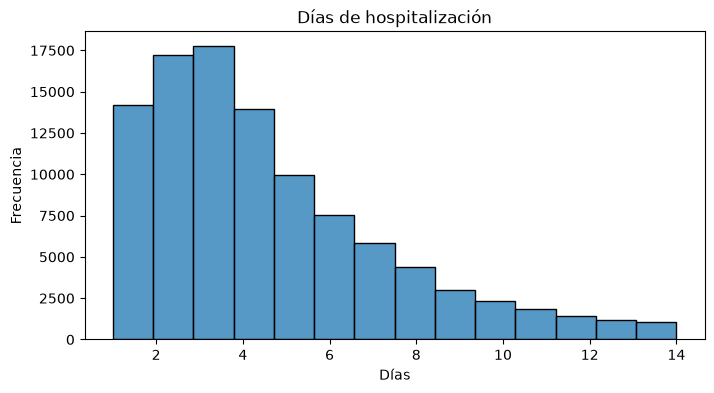

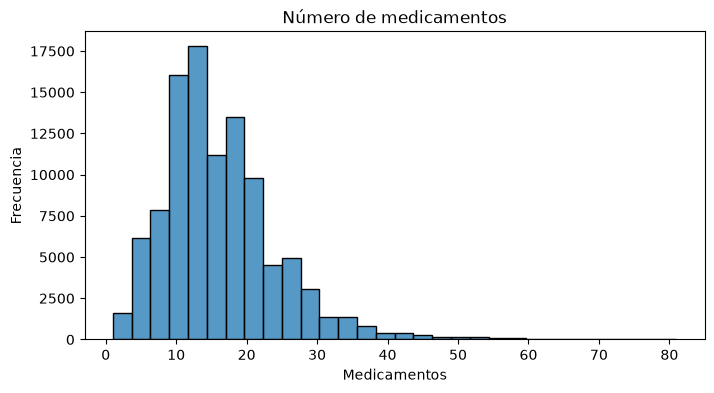

In [12]:
# Histograma de días de hospitalización

plt.figure(figsize=(8, 4))

sns.histplot(
    data=X,
    x="time_in_hospital",
    bins=14
)

plt.title("Días de hospitalización")
plt.xlabel("Días")
plt.ylabel("Frecuencia")
plt.show()


# Histograma del número de medicamentos

plt.figure(figsize=(8, 4))

sns.histplot(
    data=X,
    x="num_medications",
    bins=30
)

plt.title("Número de medicamentos")
plt.xlabel("Medicamentos")
plt.ylabel("Frecuencia")
plt.show()

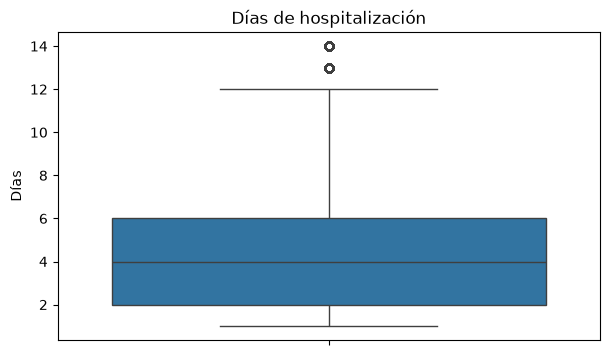

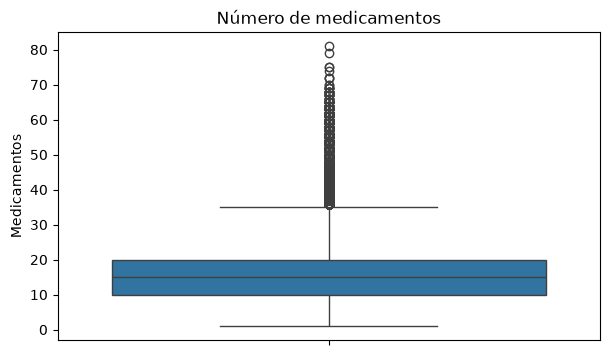

In [13]:
# Diagrama de caja de días de hospitalización

plt.figure(figsize=(7, 4))

sns.boxplot(
    y=X["time_in_hospital"]
)

plt.title("Días de hospitalización")
plt.ylabel("Días")
plt.show()


# Diagrama de caja de medicamentos

plt.figure(figsize=(7, 4))

sns.boxplot(
    y=X["num_medications"]
)

plt.title("Número de medicamentos")
plt.ylabel("Medicamentos")
plt.show()

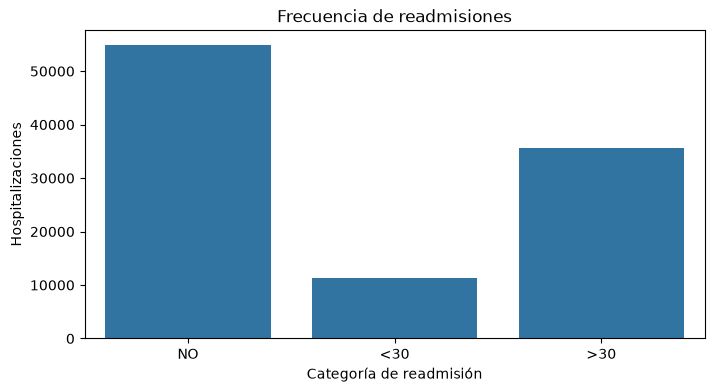

In [14]:
# Gráfico de frecuencias de readmisión

plt.figure(figsize=(8, 4))

sns.countplot(
    data=df,
    x="readmitted",
    order=["NO", "<30", ">30"]
)

plt.title("Frecuencia de readmisiones")
plt.xlabel("Categoría de readmisión")
plt.ylabel("Hospitalizaciones")
plt.show()

In [15]:
# Resumen descriptivo de las variables

for col in ["time_in_hospital", "num_medications"]:
    print("\nVariable:", col)
    print("Mínimo:", X[col].min())
    print("Máximo:", X[col].max())
    print("Media:", round(X[col].mean(), 2))
    print("Mediana:", X[col].median())

# Categoría de readmisión más frecuente
categoria_frecuente = df["readmitted"].value_counts().idxmax()

print("\nCategoría de readmisión más frecuente:")
print(categoria_frecuente)

print("\nPorcentajes:")
display(porcentajes.round(2))


Variable: time_in_hospital
Mínimo: 1
Máximo: 14
Media: 4.4
Mediana: 4.0

Variable: num_medications
Mínimo: 1
Máximo: 81
Media: 16.02
Mediana: 15.0

Categoría de readmisión más frecuente:
NO

Porcentajes:


readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

## Interpretación de los resultados de la exploración

### 1. Hospitalizaciones y pacientes

Se analizaron 101.766 hospitalizaciones correspondientes a 71.518 identificadores de pacientes únicos. Esto demuestra que la cantidad de hospitalizaciones es mayor que la cantidad de pacientes, porque algunos identificadores aparecen en varios registros. Se identificaron 30.248 registros adicionales con identificadores de pacientes repetidos, pero ninguna fila exactamente duplicada. Por lo tanto, no sería correcto eliminar todas las repeticiones de patient_nbr, ya que podríamos perder hospitalizaciones diferentes.

### 2. Duración de las hospitalizaciones

La variable time_in_hospital tiene un mínimo de 1 día, un máximo de 14 días y una media de 4,40 días. La mediana es de 4 días, lo que significa que al menos la mitad de las hospitalizaciones duró cuatro días o menos. El primer cuartil es de 2 días y el tercero de 6 días. Por tanto, la mitad central de los registros tiene duraciones comprendidas entre 2 y 6 días. Esto indica que las hospitalizaciones se concentran principalmente en duraciones relativamente cortas dentro del intervalo registrado.

### 3. Número de medicamentos

La variable num_medications presenta una media de 16,02 y una mediana de 15 medicamentos distintos por hospitalización. El primer cuartil es 10 y el tercero 20. Esto significa que la mitad central de las hospitalizaciones registra entre 10 y 20 medicamentos distintos. El máximo alcanza 81 medicamentos, considerablemente por encima de la mediana. La diferencia entre la media y la mediana indica que los valores altos influyen en el promedio, aunque esto no demuestra por sí solo la causa de esa diferencia.

### 4. Procedimientos de laboratorio

La variable num_lab_procedures presenta una media de 43,10 y una mediana de 44 pruebas. La mitad central de los registros contiene entre 31 y 57 pruebas de laboratorio. Por tanto, los registros presentan una cantidad considerable de pruebas de laboratorio, aunque sus cantidades varían entre hospitalizaciones.

### 5. Visitas previas

Las medianas de number_outpatient, number_emergency y number_inpatient son iguales a 0. Esto significa que al menos la mitad de los registros tiene cero visitas previas en cada una de esas categorías, consideradas por separado. Sin embargo, sus máximos son 42, 76 y 21, respectivamente. Por ello, la mayoría de los valores centrales son bajos, aunque también existen registros con cantidades mayores de visitas previas.

### 6. Readmisiones

La categoría `NO` presenta 54.864 hospitalizaciones, equivalentes al 53,91 %.

La categoría `>30` presenta 35.545 hospitalizaciones, equivalentes al 34,93 %.

La categoría `<30` presenta 11.357 hospitalizaciones, equivalentes al 11,16 %.

La categoría más frecuente es `NO`.

Al sumar ambas categorías de readmisión, obtenemos 46.902 hospitalizaciones, equivalentes al 46,09 %. Por lo tanto, las readmisiones registradas representan una proporción importante del conjunto analizado, aunque no podemos explicar sus causas con estas frecuencias.

### 7. Calidad de los datos

Se encontraron columnas con porcentajes elevados de valores nulos:

- `weight`: 96,86 %.
- `max_glu_serum`: 94,75 %.
- `A1Cresult`: 83,28 %.
- `medical_specialty`: 49,08 %.
- `payer_code`: 39,56 %.

La ausencia de valores registrados debe interpretarse según el significado de cada columna. Por ejemplo, un resultado de laboratorio no registrado puede estar relacionado con una prueba que no se realizó. En cambio, las siete variables cuantitativas seleccionadas para el escalamiento contienen 0 valores nulos.

### Conclusión de la exploración

El dataset contiene hospitalizaciones con características diferentes, tanto en duración como en cantidad de procedimientos, medicamentos y visitas previas. También existen diferencias importantes en la calidad de información entre columnas. La selección de las siete variables cuantitativas permite continuar con el escalamiento sin eliminar hospitalizaciones ni sustituir valores faltantes en esas siete características.



# Paso 4. Fase 3 de CRISP-DM: Selección y limpieza

## Consigna

Definir las reglas de limpieza y registrar las dimensiones de los datos antes y después de su preparación.

## Procedimiento

Se conservará una copia del dataset original.

Se seleccionarán siete variables numéricas, excluyendo los identificadores y las variables categóricas.

Se comprobará si existen valores faltantes en las características seleccionadas.

Si no existen valores faltantes, no se realizarán imputaciones.

No se eliminarán automáticamente filas duplicadas ni registros repetidos de un mismo paciente.

Los datos limpios se conservarán para realizar dos transformaciones independientes: normalización y estandarización.


In [16]:
# Guardar identificadores como referencia
referencias = df[
    ["encounter_id", "patient_nbr"]
].copy()

# Crear copia de las variables numéricas
X_clean = X.copy()

# Dimensiones antes de la limpieza
print("Antes de limpiar:", X_clean.shape)

# Comprobar valores faltantes
print("Nulos antes de limpiar:")
display(X_clean.isnull().sum())

# Convertir a valores numéricos
for columna in variables:
    X_clean[columna] = pd.to_numeric(
        X_clean[columna],
        errors="coerce"
    )

# Comprobar de nuevo los valores faltantes
print("Nulos después de convertir:")
display(X_clean.isnull().sum())

# Detener el procedimiento si existen faltantes
# para revisarlos antes de transformar.
assert X_clean.isnull().sum().sum() == 0, (
    "Existen valores faltantes. "
    "Es necesario revisar la limpieza."
)

print("Después de limpiar:", X_clean.shape)

# Mostrar las primeras filas
display(X_clean.head())

Antes de limpiar: (101766, 7)
Nulos antes de limpiar:


time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
dtype: int64

Nulos después de convertir:


time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
dtype: int64

Después de limpiar: (101766, 7)


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,1,41,0,1,0,0,0
1,3,59,0,18,0,0,0
2,2,11,5,13,2,0,1
3,2,44,1,16,0,0,0
4,1,51,0,8,0,0,0


In [17]:
# Registrar dimensiones antes y después

registro_limpieza = pd.DataFrame({
    "Etapa": [
        "Dataset original",
        "Selección de variables",
        "Datos numéricos limpios"
    ],
    "Filas": [
        df.shape[0],
        X.shape[0],
        X_clean.shape[0]
    ],
    "Columnas": [
        df.shape[1],
        X.shape[1],
        X_clean.shape[1]
    ]
})

display(registro_limpieza)

# Guardar una copia limpia
X_clean.to_csv(
    "dataset/variables_numericas_limpias.csv",
    index=False
)

# Guardar el registro
registro_limpieza.to_csv(
    "dataset/registro_limpieza.csv",
    index=False
)

,Etapa,Filas,Columnas
0,Dataset original,101766,50
1,Selección de variables,101766,7
2,Datos numéricos limpios,101766,7



# Paso 5. Selección de variables cuantitativas

## Consigna

Seleccionar las siete variables numéricas indicadas en el documento y verificar que no se incluyan identificadores o categorías.

## Variables seleccionadas

| Variable | Significado |
|---|---|
| `time_in_hospital` | Días de hospitalización |
| `num_lab_procedures` | Número de procedimientos de laboratorio |
| `num_procedures` | Número de procedimientos distintos registrados |
| `num_medications` | Número de medicamentos distintos |
| `number_outpatient` | Visitas ambulatorias previas |
| `number_emergency` | Visitas de emergencia previas |
| `number_inpatient` | Hospitalizaciones previas |

## Variables excluidas

No se escalarán:

- `encounter_id`, porque identifica una hospitalización.
- `patient_nbr`, porque identifica un paciente.
- `admission_type_id`, `discharge_disposition_id` y `admission_source_id`, porque representan categorías.
- `age`, porque contiene intervalos de edad.
- `readmitted`, porque representa una categoría de readmisión.

Las siete variables seleccionadas contienen recuentos o medidas numéricas apropiadas para practicar normalización y estandarización.


In [18]:
# Mostrar nombres y tipos de variables
print("Variables seleccionadas:")
print(X_clean.columns.tolist())

print("\nTipos de datos:")
display(X_clean.dtypes)

print("\nDimensiones:")
print(X_clean.shape)

# Verificar que tenemos siete columnas
assert X_clean.shape[1] == 7

print("\nLas siete variables están seleccionadas.")

Variables seleccionadas:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient']

Tipos de datos:


time_in_hospital      int64
num_lab_procedures    int64
num_procedures        int64
num_medications       int64
number_outpatient     int64
number_emergency      int64
number_inpatient      int64
dtype: object


Dimensiones:
(101766, 7)

Las siete variables están seleccionadas.


# Paso 6. Normalización Min-Max

## Consigna del documento

Aplicar MinMaxScaler a las siete variables seleccionadas en el intervalo [0, 1], mostrar las diez primeras filas y comprobar los límites con una tolerancia numérica.

## Fórmula de normalización Min-Max

**Valor normalizado = (valor original - mínimo) / (máximo - mínimo)**

- **Valor original:** el dato que queremos transformar.
- **Mínimo:** el menor valor registrado en esa columna.
- **Máximo:** el mayor valor registrado en esa columna.

### Ejemplo: una hospitalización de 3 días

El mínimo de time_in_hospital es 1 día y el máximo es 14 días.

1. Valor normalizado = (3 - 1) / (14 - 1)
2. Valor normalizado = 2 / 13
3. **Resultado ≈ 0,153846**

El resultado representa aproximadamente el 15,38 % del recorrido entre el mínimo y el máximo de días de hospitalización; **no** es una probabilidad de readmisión. MinMaxScaler transforma los valores constantes en 0 con esta configuración.


In [19]:
# Crear el normalizador
normalizer = preprocessing.MinMaxScaler()

# Normalizar las siete variables
X_norm = normalizer.fit_transform(X_clean)

# Convertir a DataFrame
X_norm = pd.DataFrame(
    X_norm,
    columns=X_clean.columns,
    index=X_clean.index
)

# Mostrar las primeras diez filas
display(X_norm.head(10))

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000


In [20]:
# Estadísticas antes de normalizar
print("Datos originales:")
display(X_clean.describe())

# Estadísticas después de normalizar
print("Datos normalizados:")
display(X_norm.describe())

# Comparar mínimos y máximos
tabla_minmax = pd.DataFrame({
    "Mínimo original": X_clean.min(),
    "Máximo original": X_clean.max(),
    "Mínimo normalizado": X_norm.min(),
    "Máximo normalizado": X_norm.max()
})

display(tabla_minmax)

# Comprobar el rango [0, 1]
assert (
    (X_norm >= -1e-10)
    & (X_norm <= 1 + 1e-10)
).all().all()

print("Normalización comprobada.")

Datos originales:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000


Datos normalizados:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,0.261230,0.321341,0.223288,0.187773,0.008794,0.002603,0.030265
std,0.229624,0.150186,0.284301,0.101595,0.030173,0.012243,0.060136
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.076923,0.229008,0.000000,0.112500,0.000000,0.000000,0.000000
50%,0.230769,0.328244,0.166667,0.175000,0.000000,0.000000,0.000000
75%,0.384615,0.427481,0.333333,0.237500,0.000000,0.000000,0.047619
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


,Mínimo original,Máximo original,Mínimo normalizado,Máximo normalizado
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


Normalización comprobada.


# Paso 7. Estandarización Z-score

## Consigna del documento

Aplicar StandardScaler a otra copia de las siete variables limpias, no al resultado de Min-Max. Mostrar diez filas y comprobar medias cercanas a cero y desviaciones cercanas a uno usando ddof=0 y tolerancia.

## Fórmula de estandarización Z-score

**Valor estandarizado = (valor original - media) / desviación estándar**

- **Valor original:** el dato que deseamos transformar.
- **Media:** el promedio de la característica.
- **Desviación estándar:** medida de dispersión utilizada por StandardScaler (ddof=0).

### Ejemplo: una hospitalización de 3 días

- Media de time_in_hospital ≈ 4,395987 días.
- Desviación estándar ≈ 2,985093 días.

1. Valor estandarizado = (3 - 4,395987) / 2,985093
2. **Resultado ≈ -0,467653**

El signo negativo indica que 3 días está por debajo de la media; equivale aproximadamente a 0,47 desviaciones estándar por debajo. A diferencia de Min-Max, Z-score puede dar valores negativos y mayores que 1. Si una característica es constante, StandardScaler da 0 para todos sus valores y la desviación estándar del resultado es 0.


In [21]:
# Crear el estandarizador
standarizer = preprocessing.StandardScaler()

# Estandarizar los datos limpios originales
# No utilizamos X_norm
X_std = standarizer.fit_transform(X_clean.copy())

# Convertir el resultado a DataFrame
X_std = pd.DataFrame(
    X_std,
    columns=X_clean.columns,
    index=X_clean.index
)

# Mostrar las primeras diez filas
display(X_std.head(10))

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276


In [22]:
# Mostrar las primeras diez filas estandarizadas.
print("Primeras diez filas:")
display(X_std.head(10))

# Calcular media y desviación con ddof=0.
tabla_std = pd.DataFrame({
    "Media": X_std.mean(),
    "Desviación estándar (ddof=0)": X_std.std(ddof=0)
})

print("Comprobación de StandardScaler:")
display(tabla_std)

# Tolerancia numérica.
tolerancia = 1e-10

# Comprobar media aproximadamente cero.
assert np.allclose(
    X_std.mean().to_numpy(),
    0,
    atol=tolerancia
)

# Identificar columnas constantes.
no_constantes = X_clean.std(ddof=0) > 0

# Las no constantes deben tener desviación 1.
assert np.allclose(
    X_std.loc[:, no_constantes]
    .std(ddof=0).to_numpy(),
    1,
    atol=tolerancia
)

# Las constantes deben transformarse en ceros.
if (~no_constantes).any():
    assert np.allclose(
        X_std.loc[:, ~no_constantes].to_numpy(),
        0,
        atol=tolerancia
    )

print("Columnas constantes:",
      list(X_clean.columns[~no_constantes]))

print("Estandarización verificada.")

Primeras diez filas:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276


Comprobación de StandardScaler:


,Media,Desviación estándar (ddof=0)
time_in_hospital,5.809126e-17,1.0
num_lab_procedures,1.161825e-16,1.0
num_procedures,-6.479410e-17,1.0
num_medications,-1.340568e-16,1.0
number_outpatient,3.574847e-17,1.0
number_emergency,1.787424e-17,1.0
number_inpatient,-3.574847e-17,1.0


Columnas constantes: []
Estandarización verificada.



## Interpretación de la estandarización

Los resultados de las siete características muestran medias aproximadamente iguales a 0 y desviaciones estándar iguales a 1 utilizando ddof=0. Esto confirma que StandardScaler aplicó correctamente la estandarización.

### ¿Por qué aparecen valores negativos?

Porque algunos registros tienen valores inferiores a la media de su característica. Por ejemplo, una hospitalización de 3 días se transforma aproximadamente en -0,467653, ya que es más corta que la duración media de 4,395987 días.

### ¿Por qué aparecen valores superiores a 1?

Porque una observación puede encontrarse a más de una desviación estándar por encima de la media. En number_emergency, el valor estandarizado máximo es aproximadamente 81,47. Esto indica que el máximo original se encuentra a muchas desviaciones estándar de la media de esa característica. El resultado de StandardScaler no está limitado al intervalo [0, 1].

### ¿Qué sucede con una columna constante?

Si todos sus valores originales son iguales, StandardScaler produce valores 0. Su desviación estándar transformada será 0 en lugar de 1. En el conjunto analizado, ninguna de las siete características seleccionadas fue constante.



# Paso 8. Comparación y exportación

## Consigna

Comparar las estadísticas descriptivas de las siete variables antes y después del escalamiento.

Mostrar gráficos de dos variables en sus tres versiones.

Realizar cinco ejemplos de normalización y estandarización mediante sus fórmulas y comparar los resultados con Python.

Finalmente, exportar los datos normalizados y estandarizados a archivos CSV.

## Comparación conceptual

La normalización Min-Max utiliza el mínimo y el máximo.

La estandarización Z-score utiliza la media y la desviación estándar.

Ambas técnicas modifican la escala de los valores, pero utilizan parámetros diferentes.


In [23]:
# Crear estadísticas para cada versión

def resumen(datos, nombre):
    tabla = pd.DataFrame({
        "Variable": datos.columns,
        "Versión": nombre,
        "Mínimo": datos.min().values,
        "Máximo": datos.max().values,
        "Media": datos.mean().values,
        "Desviación": datos.std(ddof=0).values
    })

    return tabla


# Comparar las tres versiones
comparacion = pd.concat([
    resumen(X_clean, "Original"),
    resumen(X_norm, "Normalizado"),
    resumen(X_std, "Estandarizado")
], ignore_index=True)

display(comparacion.round(4))

# Exportar la tabla
comparacion.to_csv(
    "dataset/comparacion_estadistica.csv",
    index=False
)

,Variable,Versión,Mínimo,Máximo,Media,Desviación
0,time_in_hospital,Original,1.0000,14.0000,4.3960,2.9851
1,num_lab_procedures,Original,1.0000,132.0000,43.0956,19.6743
2,num_procedures,Original,0.0000,6.0000,1.3397,1.7058
3,num_medications,Original,1.0000,81.0000,16.0218,8.1275
4,number_outpatient,Original,0.0000,42.0000,0.3694,1.2673
5,number_emergency,Original,0.0000,76.0000,0.1978,0.9305
6,number_inpatient,Original,0.0000,21.0000,0.6356,1.2629
7,time_in_hospital,Normalizado,0.0000,1.0000,0.2612,0.2296
8,num_lab_procedures,Normalizado,0.0000,1.0000,0.3213,0.1502
9,num_procedures,Normalizado,0.0000,1.0000,0.2233,0.2843


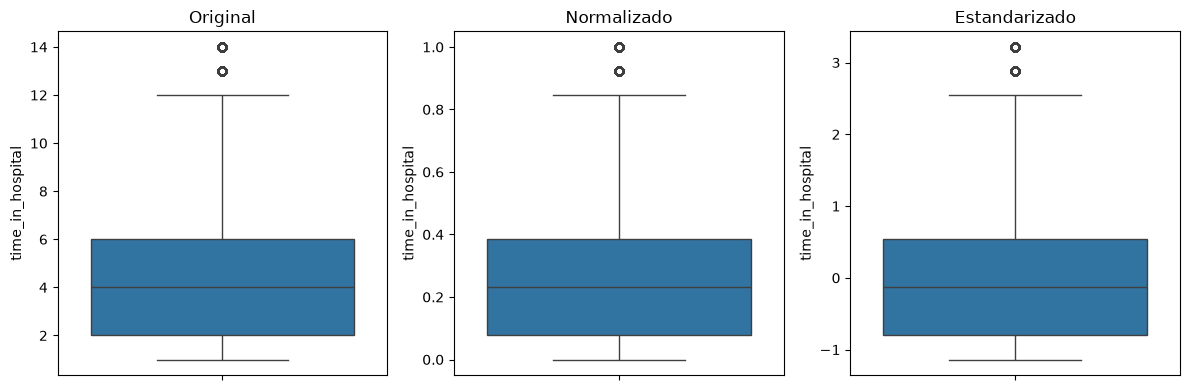

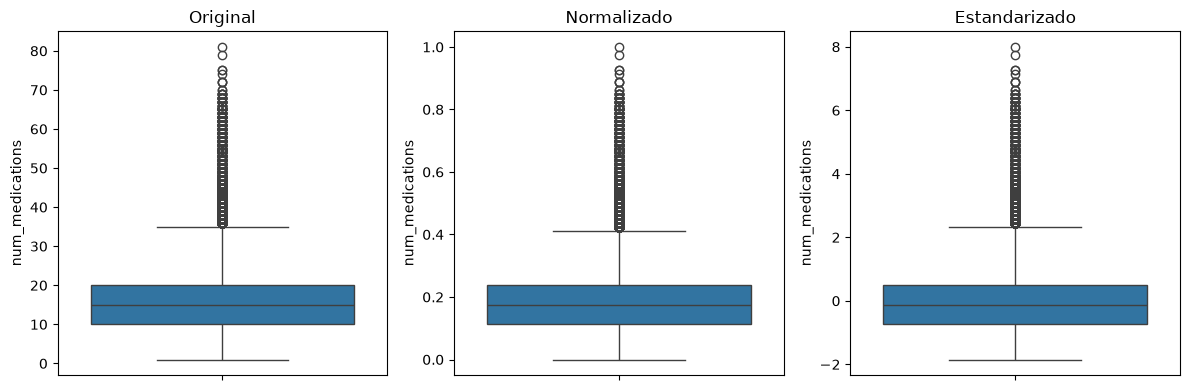

In [24]:
# Comparación de días de hospitalización

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.boxplot(y=X_clean["time_in_hospital"])
plt.title("Original")

plt.subplot(1, 3, 2)
sns.boxplot(y=X_norm["time_in_hospital"])
plt.title("Normalizado")

plt.subplot(1, 3, 3)
sns.boxplot(y=X_std["time_in_hospital"])
plt.title("Estandarizado")

plt.tight_layout()
plt.show()


# Comparación del número de medicamentos

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.boxplot(y=X_clean["num_medications"])
plt.title("Original")

plt.subplot(1, 3, 2)
sns.boxplot(y=X_norm["num_medications"])
plt.title("Normalizado")

plt.subplot(1, 3, 3)
sns.boxplot(y=X_std["num_medications"])
plt.title("Estandarizado")

plt.tight_layout()
plt.show()

## Interpretación de la comparación de las tres versiones

### 1. Diferencias entre las variables originales

Las siete características no comparten una misma escala.
Por ejemplo:

- `time_in_hospital`: valores entre 1 y 14 días.
- `num_lab_procedures`: valores entre 1 y 132 pruebas.
- `num_medications`: valores entre 1 y 81 medicamentos.
- `number_emergency`: valores entre 0 y 76 visitas.

Esto significa que sus rangos numéricos son diferentes, aunque todas las variables representan características de las hospitalizaciones. La diferencia de magnitudes puede influir en algoritmos de Machine Learning que utilizan distancias o son sensibles a la escala.

### 2. Resultados de la normalización Min-Max

Después de aplicar MinMaxScaler, todas las características tienen mínimo 0 y máximo 1. Sin embargo, sus medias normalizadas siguen siendo diferentes:

- `time_in_hospital`: 0,2612.
- `num_lab_procedures`: 0,3213.
- `num_medications`: 0,1878.
- `number_emergency`: 0,0026.

Esto demuestra que normalizar no significa que todas las variables tengan el mismo promedio. En number_emergency, la media normalizada de 0,0026 es muy cercana al mínimo, porque el promedio original es aproximadamente 0,20 visitas mientras que el máximo registrado es 76. Por tanto, cuando una característica tiene un máximo muy alejado de sus valores habituales, la normalización puede concentrar muchos resultados cerca de 0.

### 3. Resultados de la estandarización Z-score

Después de aplicar StandardScaler, las siete características presentan medias aproximadamente iguales a 0 y desviaciones estándar iguales a 1. A diferencia de Min-Max, los valores no están limitados al intervalo [0, 1].
Por ejemplo:

- El máximo estandarizado de `time_in_hospital` es 3,2173.
- El máximo estandarizado de `num_medications` es 7,9948.
- El máximo estandarizado de `number_emergency` es 81,4667.

Esto demuestra que las observaciones máximas se encuentran a distancias diferentes respecto a las medias de sus propias variables.

### 4. Interpretación de los gráficos comparativos

Los gráficos de time_in_hospital y num_medications muestran las mismas observaciones en tres escalas diferentes.

Los valores originales conservan sus unidades.

Los valores normalizados expresan su posición entre el mínimo y el máximo.

Los valores estandarizados expresan su distancia respecto a la media.

Las transformaciones no cambian el orden de las observaciones ni la forma relativa de las distribuciones de características no constantes, aunque las escalas de los ejes sean diferentes.

### 5. Comprobación de los cálculos manuales

Se seleccionaron los primeros cinco valores de time_in_hospital: 1, 3, 2, 2 y 1. El valor original de 3 días se transformó en:

- Min-Max: 0,153846.
- Z-score: -0,467653.

Los resultados calculados mediante las fórmulas coincidieron con los producidos por Scikit-learn. Esto confirma que ambas técnicas aplicaron sus respectivas operaciones matemáticas a los mismos datos originales limpios.

### Conclusión de la comparación

La práctica demuestra que normalización y estandarización no son procedimientos equivalentes. Min-Max fija un intervalo numérico para las características, pero no iguala sus medias. Z-score centra las características alrededor de cero y ajusta su dispersión, pero permite valores negativos y superiores a 1. Los dos métodos son útiles para preparar datos, aunque la selección dependerá de los requisitos del algoritmo que se utilice posteriormente.


In [25]:
# Seleccionamos una variable
variable = "time_in_hospital"

# Obtener parámetros
minimo = X_clean[variable].min()
maximo = X_clean[variable].max()
media = X_clean[variable].mean()
desviacion = X_clean[variable].std(ddof=0)

# Tomar cinco valores originales
valores = X_clean[variable].head(5)

print("Mínimo:", minimo)
print("Máximo:", maximo)
print("Media:", media)
print("Desviación:", desviacion)

# Aplicar fórmula Min-Max
if maximo != minimo:
    calculo_minmax = (
        (valores - minimo) / (maximo - minimo)
    )
else:
    calculo_minmax = valores * 0.0

# Aplicar fórmula Z-score
if desviacion != 0:
    calculo_zscore = (
        (valores - media) / desviacion
    )
else:
    calculo_zscore = valores * 0.0

# Comparar con Scikit-learn
tabla_calculos = pd.DataFrame({
    "Original": valores,
    "Min-Max manual": calculo_minmax,
    "Min-Max Python": X_norm.loc[
        valores.index, variable
    ],
    "Z-score manual": calculo_zscore,
    "Z-score Python": X_std.loc[
        valores.index, variable
    ]
})

display(tabla_calculos.round(6))

Mínimo: 1
Máximo: 14
Media: 4.395986871843248
Desviación: 2.985093100907283


,Original,Min-Max manual,Min-Max Python,Z-score manual,Z-score Python
0,1,0.000000,0.000000,-1.137649,-1.137649
1,3,0.153846,0.153846,-0.467653,-0.467653
2,2,0.076923,0.076923,-0.802651,-0.802651
3,2,0.076923,0.076923,-0.802651,-0.802651
4,1,0.000000,0.000000,-1.137649,-1.137649


In [26]:
# Mostrar las operaciones matemáticas

for x in valores:

    if maximo != minimo:
        minmax = (x - minimo) / (maximo - minimo)
    else:
        minmax = 0.0

    if desviacion != 0:
        zscore = (x - media) / desviacion
    else:
        zscore = 0.0

    print(f"Valor original: {x}")

    print(
        f"Min-Max: ({x} - {minimo}) / "
        f"({maximo} - {minimo}) = {minmax:.6f}"
    )

    print(
        f"Z-score: ({x} - {media:.6f}) / "
        f"{desviacion:.6f} = {zscore:.6f}"
    )

    print("------------------------------")


# Verificar los cálculos
assert np.allclose(
    tabla_calculos["Min-Max manual"],
    tabla_calculos["Min-Max Python"]
)

assert np.allclose(
    tabla_calculos["Z-score manual"],
    tabla_calculos["Z-score Python"]
)

print("Los cálculos coinciden.")

Valor original: 1
Min-Max: (1 - 1) / (14 - 1) = 0.000000
Z-score: (1 - 4.395987) / 2.985093 = -1.137649
------------------------------
Valor original: 3
Min-Max: (3 - 1) / (14 - 1) = 0.153846
Z-score: (3 - 4.395987) / 2.985093 = -0.467653
------------------------------
Valor original: 2
Min-Max: (2 - 1) / (14 - 1) = 0.076923
Z-score: (2 - 4.395987) / 2.985093 = -0.802651
------------------------------
Valor original: 2
Min-Max: (2 - 1) / (14 - 1) = 0.076923
Z-score: (2 - 4.395987) / 2.985093 = -0.802651
------------------------------
Valor original: 1
Min-Max: (1 - 1) / (14 - 1) = 0.000000
Z-score: (1 - 4.395987) / 2.985093 = -1.137649
------------------------------
Los cálculos coinciden.


In [27]:
# Comprobar dimensiones y orden de filas
assert len(X_clean) == len(X_norm)
assert len(X_clean) == len(X_std)

assert X_clean.index.equals(X_norm.index)
assert X_clean.index.equals(X_std.index)

# Guardar datos normalizados
X_norm.to_csv(
    "dataset/datos_normalizados.csv",
    index=False
)

# Guardar datos estandarizados
X_std.to_csv(
    "dataset/datos_estandarizados.csv",
    index=False
)

# Guardar la posición original de cada hospitalización.
if "fila_original" not in referencias.columns:
    referencias.insert(0, "fila_original", X_clean.index)

# Comprobar la correspondencia por posición.
assert len(referencias) == len(X_norm)
assert len(referencias) == len(X_std)

# Guardar identificadores separados
referencias.to_csv(
    "dataset/referencias_hospitalizaciones.csv",
    index=False
)

print("Archivos guardados correctamente.")

Archivos guardados correctamente.



# Preguntas de reflexión

## 1. ¿Por qué un código categórico numérico no debe escalarse como una medición?

Porque un número puede representar una categoría en lugar de una cantidad. Por ejemplo, el código de un tipo de admisión no es una medida continua.

## 2. ¿Cómo afectaría un valor extremo a Min-Max y a Z-score?

Min-Max utiliza el mínimo y el máximo de la variable. Por eso, un valor extremo puede ampliar el rango utilizado y concentrar otros valores normalizados en una parte pequeña del intervalo. Z-score utiliza la media y la desviación estándar. Un valor extremo puede modificar ambos parámetros. Esta respuesta se limita al comportamiento de las transformaciones, sin aplicar técnicas de detección de outliers.

## 3. ¿Por qué una readmisión del mismo paciente no es necesariamente un duplicado?

Porque una persona puede ser hospitalizada en varias ocasiones. Aunque el identificador del paciente sea el mismo, las hospitalizaciones pueden corresponder a eventos diferentes.

## 4. ¿Qué diferencia existe entre cambiar de escala y corregir una distribución asimétrica?

Cambiar de escala modifica la representación numérica de los valores. Una transformación lineal como Min-Max o Z-score no corrige automáticamente la asimetría de la distribución.

## 5. ¿Cómo evitaría la fuga de información si posteriormente entrenara un modelo?

Separaría los datos de entrenamiento y prueba antes de ajustar el escalador. Calcularía los parámetros del escalamiento únicamente con el conjunto de entrenamiento y los utilizaría para transformar los datos de prueba. También tendría en cuenta los registros repetidos de un mismo paciente al definir las particiones. En esta práctica no se entrenan modelos, por lo que este procedimiento se menciona únicamente como consideración para un trabajo posterior.


# Conclusiones

## 1. Comprensión del negocio

El análisis permitió examinar las hospitalizaciones de pacientes con diabetes y estudiar descriptivamente las categorías de readmisión. El conjunto contiene 101.766 hospitalizaciones correspondientes a 71.518 identificadores de pacientes únicos. Esta diferencia confirma la importancia de distinguir las hospitalizaciones de las personas, porque algunos pacientes tienen varios registros.

## 2. ¿Cuál fue la categoría de readmisión más frecuente?

La categoría más frecuente fue NO, con 54.864 hospitalizaciones, equivalentes al 53,91 %. Las categorías >30 y <30 reunieron 46.902 hospitalizaciones, equivalentes al 46,09 %. Por tanto, aunque la categoría NO representa la mayoría, las readmisiones registradas también constituyen una proporción importante del conjunto. Estos resultados describen la distribución de la variable, pero no permiten establecer las causas de las readmisiones.

## 3. ¿Qué aprendimos de las variables cuantitativas?

La duración media de hospitalización fue de 4,40 días y su mediana de 4 días. La mitad central de los registros presentó duraciones entre 2 y 6 días. El número de medicamentos distintos registró una media de 16,02 y una mediana de 15. La mitad central de los registros estuvo entre 10 y 20 medicamentos. Las tres variables de visitas anteriores presentaron medianas iguales a cero, lo que muestra una concentración importante de observaciones con pocas visitas previas. Los resultados evidencian diferencias en las magnitudes y dispersiones de las características seleccionadas.

## 4. ¿Qué aprendimos de la calidad de los datos?

Se encontraron valores faltantes en algunas columnas del conjunto original, especialmente en weight, max_glu_serum y A1Cresult. No obstante, las siete variables cuantitativas seleccionadas para el escalamiento contenían cero valores nulos. No se encontraron filas exactamente duplicadas. Se conservaron las 101.766 hospitalizaciones, evitando eliminar automáticamente registros que comparten un identificador de paciente.

## 5. ¿Qué demostró la normalización?

La normalización Min-Max transformó los mínimos y máximos de las siete características al intervalo [0, 1]. Sin embargo, las medias transformadas no fueron iguales. Por ejemplo, la media normalizada de time_in_hospital fue 0,2612, mientras que la de number_emergency fue 0,0026. Esto permite comprender que normalizar los extremos no significa igualar las distribuciones de las variables.

## 6. ¿Qué demostró la estandarización?

La estandarización Z-score produjo características con media aproximadamente cero y desviación estándar igual a uno utilizando ddof=0. También se observaron valores negativos y superiores a uno. Por ejemplo, el valor máximo estandarizado de number_emergency fue aproximadamente 81,47. Esto muestra que StandardScaler permite representar las observaciones según su distancia respecto a la media y no limita los resultados a un intervalo de 0 a 1.

## 7. Diferencias entre ambas técnicas

Min-Max utiliza el mínimo y el máximo de cada característica.

Z-score utiliza la media y la desviación estándar.

Ambos métodos cambian la escala, pero no modifican automáticamente la forma relativa de las distribuciones. Las dos técnicas se aplicaron de manera independiente a las siete variables originales limpias.

## Conclusión general

La práctica permitió comprender que el preprocesamiento requiere conocer previamente los datos, revisar su calidad, seleccionar correctamente las variables y justificar las transformaciones. Los resultados mostraron diferencias importantes entre las magnitudes de las características hospitalarias. La normalización y la estandarización permitieron representar esas características de formas distintas, conservando la correspondencia con los registros originales. Este trabajo se limitó a los procedimientos estudiados hasta el tema 1.4.2, sin desarrollar la detección de outliers del tema 1.4.3. El análisis tiene carácter académico y descriptivo. No permite emitir diagnósticos individuales ni establecer relaciones causales. 


# Referencias bibliográficas

Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

UCI Machine Learning Repository. (s. f.). *Diabetes 130-US Hospitals for Years 1999–2008*. https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

Scikit-learn. (s. f.). *MinMaxScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html

Scikit-learn. (s. f.). *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

## Declaración de asistencia

Se utilizó ChatGPT como apoyo para organizar las celdas del notebook, comprender las instrucciones del documento y explicar las funciones de Python utilizadas.
